# Notebook 1 · Implementación de una DCGAN para generar rostros humanos

**Especialización en Inteligencia Artificial – Universidad de Cundinamarca**<br>
**Asignatura:** Deep Learning – Conceptos (604013) · **Actividad:** R2-A5-S14 Generación

En este notebook construí desde cero una **Red Generativa Adversaria Convolucional Profunda (DCGAN)** para generar rostros que no existen. Seguí la idea del artículo *Implementing a Generative Adversarial Network (GAN/DCGAN) to Draw Human Faces*, que a su vez se basa en el trabajo de Radford, Metz y Chintala (2015).

La idea de fondo me gusta explicarla como el juego entre un falsificador y un policía:
- El **generador** es el falsificador. Parte de puro ruido aleatorio e intenta fabricar una cara que parezca real.
- El **discriminador** es el policía. Recibe caras reales y caras falsas y tiene que decir cuáles son cuáles.

Los dos se entrenan al mismo tiempo. Cada vez que el policía detecta una falsificación, el falsificador aprende de su error y mejora, y cada vez que el falsificador mejora, el policía se ve obligado a fijarse en detalles más finos.

**Requisito:** ejecutar en Google Colab con GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*).

## 1. Librerías y configuración del dispositivo

In [1]:
!pip -q install datasets

In [2]:
import os, time, json, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.utils as vutils
import torchvision.transforms as T
from tqdm.auto import tqdm

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "sin GPU (el entrenamiento será muy lento)")

os.makedirs("figuras", exist_ok=True); os.makedirs("modelos", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

PyTorch: 2.14.1+cu130
Dispositivo: cuda | Tesla T4


## 2. Antes de la DCGAN: una GAN mínima hecha a mano ("Slanted Land")

Antes de pasar a las convoluciones quise reproducir el ejemplo que vimos en clase: un mundo de pantallas de **2×2 píxeles** donde una "cara" es una diagonal oscura (píxeles 1 y 4 altos, 2 y 3 bajos). Este ejemplo, popularizado por Luis Serrano, permite ver toda la matemática de una GAN sin que ninguna librería la esconda:

- **Discriminador:** una sola neurona, $D(x) = \sigma(w \cdot x + b)$. Una salida cercana a 1 significa "es una cara" y cercana a 0 significa "es ruido".
- **Generador:** recibe un número aleatorio $z \in [0, 1]$ y produce los 4 píxeles con $G(z) = \sigma(v\,z + c)$.
- **Errores (logaritmo natural):**
  - Para el discriminador, $-\ln D(x)$ con las caras reales y $-\ln(1 - D(G(z)))$ con las falsas.
  - Para el generador, $-\ln D(G(z))$.
- **Derivadas:** las calculé a mano con la regla de la cadena y actualizo los pesos por descenso del gradiente. Es exactamente lo que hace *backpropagation* en las redes grandes.

Todo está escrito con NumPy, sin PyTorch.

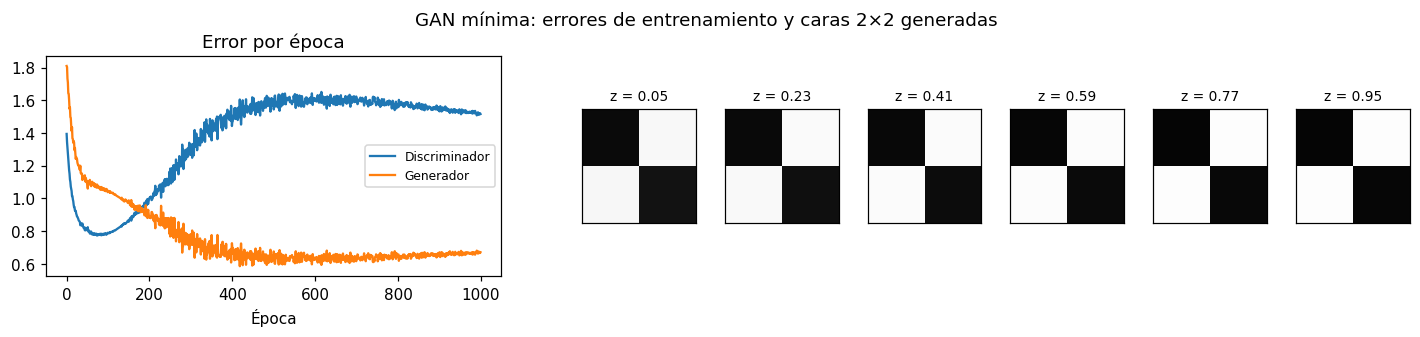

Pesos aprendidos por el discriminador (p1, p2, p3, p4): [ 1.1  -0.29 -0.89  0.37] | sesgo: -1.34
Ejemplo de cara generada (z = 0.5): [0.97 0.03 0.03 0.96]
D(cara real) = 0.534 | D(ruido uniforme) = 0.34


In [3]:
sigmoide = lambda x: 1 / (1 + np.exp(-x))

# Caras de 2x2 aplanadas [p1, p2, p3, p4]: diagonal principal alta, la otra baja
caras = np.array([[1.0, 0.0, 0.0, 1.0],
                  [0.9, 0.1, 0.2, 0.8],
                  [0.9, 0.2, 0.1, 0.8],
                  [0.8, 0.1, 0.2, 0.9],
                  [0.8, 0.2, 0.1, 0.9]])

class DiscriminadorMini:
    def __init__(self, rng):
        self.w, self.b = rng.normal(size=4), rng.normal()
    def forward(self, x):
        return sigmoide(x @ self.w + self.b)
    def paso_real(self, x, lr):                 # error = -ln D(x)
        d = self.forward(x)
        self.w -= lr * (-x * (1 - d)); self.b -= lr * (-(1 - d))
        return -np.log(d)
    def paso_falso(self, x, lr):                # error = -ln(1 - D(x))
        d = self.forward(x)
        self.w -= lr * (x * d); self.b -= lr * d
        return -np.log(1 - d)

class GeneradorMini:
    def __init__(self, rng):
        self.v, self.c = rng.normal(size=4), rng.normal(size=4)
    def forward(self, z):
        return sigmoide(self.v * z + self.c)
    def paso(self, z, D, lr):                   # error = -ln D(G(z)), regla de la cadena
        x = self.forward(z); d = D.forward(x)
        dE_dx = -(1 - d) * D.w                  # derivada del error respecto a cada píxel generado
        dx_da = x * (1 - x)                     # derivada de la sigmoide
        self.v -= lr * dE_dx * dx_da * z; self.c -= lr * dE_dx * dx_da
        return -np.log(d)

rng = np.random.default_rng(SEMILLA)
Dm, Gm = DiscriminadorMini(rng), GeneradorMini(rng)
err_D, err_G = [], []
for epoca in range(1000):
    eD = eG = 0
    for cara in caras:
        z = rng.random()
        eD += Dm.paso_real(cara, 0.01) + Dm.paso_falso(Gm.forward(z), 0.01)
        eG += Gm.paso(z, Dm, 0.01)
    err_D.append(eD / len(caras)); err_G.append(eG / len(caras))

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6), gridspec_kw={"width_ratios": [4, 0.2, 1, 1, 1, 1, 1, 1]})
axes[0].plot(err_D, label="Discriminador"); axes[0].plot(err_G, label="Generador")
axes[0].set_title("Error por época"); axes[0].set_xlabel("Época"); axes[0].legend(fontsize=8)
axes[1].axis("off")
for k, z in enumerate(np.linspace(0.05, 0.95, 6)):
    axes[k + 2].imshow(Gm.forward(z).reshape(2, 2), cmap="Greys", vmin=0, vmax=1)
    axes[k + 2].set_title(f"z = {z:.2f}", fontsize=9); axes[k + 2].set_xticks([]); axes[k + 2].set_yticks([])
plt.suptitle("GAN mínima: errores de entrenamiento y caras 2×2 generadas", y=1.04)
plt.savefig("figuras/gan_mini_slanted.png", bbox_inches="tight"); plt.show()

print("Pesos aprendidos por el discriminador (p1, p2, p3, p4):", np.round(Dm.w, 2), "| sesgo:", round(Dm.b, 2))
print("Ejemplo de cara generada (z = 0.5):", np.round(Gm.forward(0.5), 2))
print("D(cara real) =", round(float(Dm.forward(caras[0])), 3), "| D(ruido uniforme) =", round(float(Dm.forward(rng.random(4))), 3))

Lo bonito de este ejemplo es que se puede leer directamente lo que aprendió cada red. El discriminador termina con pesos **positivos en la diagonal principal** (píxeles 1 y 4) y **negativos en la otra** (píxeles 2 y 3): aprendió por sí solo la regla "sumo la diagonal y resto los opuestos" que hicimos a mano en clase. Por su parte, el generador produce diagonales oscuras para cualquier valor de z. La DCGAN de las siguientes secciones hace exactamente lo mismo, solo que con millones de parámetros y capas convolucionales en lugar de una neurona.

## 3. DCGAN: hiperparámetros

Para la DCGAN usé los valores que recomienda el paper de DCGAN: imágenes de 64×64, vector latente de 100 dimensiones, Adam con tasa de aprendizaje de 0,0002 y β₁ = 0,5. Para que todo el proceso quepa en una sesión gratuita de Colab trabajé con un subconjunto de 40.000 rostros y 15 épocas.

In [4]:
N_IMAGENES = 40_000     # subconjunto de CelebA
TAM_IMAGEN = 64         # resolución de trabajo (64x64)
NZ = 100                # dimensión del espacio latente (vector de ruido z)
NGF = 64                # filtros base del generador
NDF = 64                # filtros base del discriminador
EPOCAS = 15
BATCH = 128
LR = 2e-4
BETA1 = 0.5
ETIQUETA_REAL = 0.9     # suavizado de etiquetas de un solo lado (ver sección 5)

### 3.1 Preparación de los datos: CelebA

Trabajé con **CelebA**, un conjunto de más de 200.000 fotos de rostros de celebridades que es el que usa el artículo de referencia. Lo cargo desde Hugging Face en modo *streaming* para no tener que descargar el dataset completo; solo leo las primeras 40.000 imágenes.

Cada imagen pasa por tres transformaciones:
1. **Recorte central** de 148 px, para quedarme con la cara y quitar fondo.
2. **Redimensionamiento** a 64×64 px.
3. **Normalización** al rango [−1, 1], para que coincida con la salida *tanh* del generador.

Guardo las imágenes como enteros de 8 bits en memoria (unos 490 MB) y las normalizo en la GPU al momento de entrenar. Así la carga de datos no frena el entrenamiento.

In [5]:
from datasets import load_dataset

ds = load_dataset("nielsr/CelebA-faces", split="train", streaming=True)
preprocesar = T.Compose([T.CenterCrop(148), T.Resize(TAM_IMAGEN, antialias=True)])

t0 = time.time()
imagenes = np.empty((N_IMAGENES, TAM_IMAGEN, TAM_IMAGEN, 3), dtype=np.uint8)
for i, ejemplo in enumerate(tqdm(ds.take(N_IMAGENES), total=N_IMAGENES, desc="Cargando rostros")):
    imagenes[i] = np.asarray(preprocesar(ejemplo["image"].convert("RGB")))
print(f"Imágenes cargadas: {imagenes.shape} en {time.time() - t0:.0f} s")

dataset_infos.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

Cargando rostros:   0%|          | 0/40000 [00:00<?, ?it/s]

Imágenes cargadas: (40000, 64, 64, 3) en 40 s


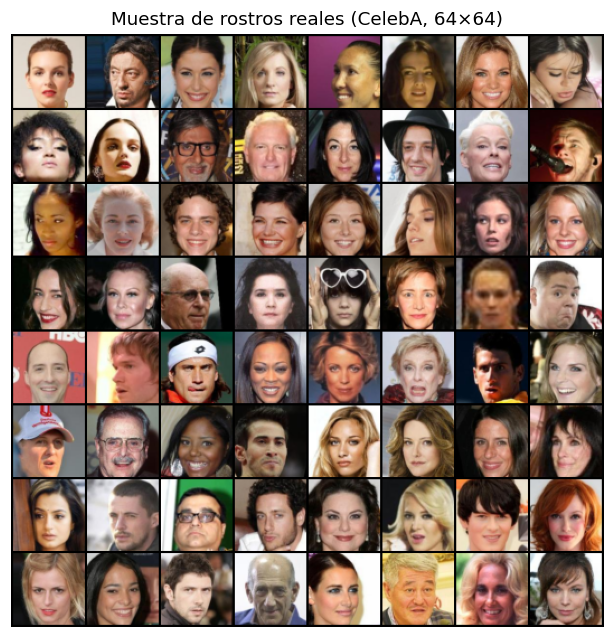

Lotes por época: 312


In [6]:
datos = torch.from_numpy(imagenes).permute(0, 3, 1, 2).contiguous()   # (N, 3, 64, 64) uint8
cargador = torch.utils.data.DataLoader(datos, batch_size=BATCH, shuffle=True, drop_last=True)

def a_rango_red(x_uint8):
    # uint8 [0, 255] -> float [-1, 1] en el dispositivo
    return x_uint8.to(device, non_blocking=True).float() / 127.5 - 1.0

def mostrar_rejilla(lote, titulo, archivo=None, nrow=8):
    rejilla = vutils.make_grid(lote[:nrow * nrow], nrow=nrow, padding=2, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(7, 7)); plt.axis("off"); plt.title(titulo)
    plt.imshow(rejilla.permute(1, 2, 0).cpu().numpy())
    if archivo: plt.savefig(archivo, bbox_inches="tight")
    plt.show()

muestra_real = a_rango_red(next(iter(cargador)))
mostrar_rejilla(muestra_real, "Muestra de rostros reales (CelebA, 64×64)", "figuras/gan_reales.png")
print("Lotes por época:", len(cargador))

## 4. Arquitectura

### 4.1 Generador
El generador recibe un vector de ruido **z** de 100 números tomados de una distribución normal (eso es el **espacio latente**) y lo va "inflando" con **convoluciones transpuestas** hasta llegar a una imagen de 64×64×3:

`z (100×1×1) → 512×4×4 → 256×8×8 → 128×16×16 → 64×32×32 → 3×64×64`

Siguiendo las pautas del paper de DCGAN, uso *Batch Normalization* y ReLU en las capas intermedias y **tanh** a la salida, para que los píxeles queden entre −1 y 1. No hay capas densas ni *pooling*: todo el cambio de tamaño lo hacen las convoluciones.

In [7]:
class Generador(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF):
        super().__init__()
        def bloque(c_in, c_out, k=4, s=2, p=1):
            return [nn.ConvTranspose2d(c_in, c_out, k, s, p, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(True)]
        self.red = nn.Sequential(
            *bloque(nz, ngf * 8, 4, 1, 0),      # 1x1   -> 4x4
            *bloque(ngf * 8, ngf * 4),          # 4x4   -> 8x8
            *bloque(ngf * 4, ngf * 2),          # 8x8   -> 16x16
            *bloque(ngf * 2, ngf),              # 16x16 -> 32x32
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False),   # 32x32 -> 64x64
            nn.Tanh(),
        )

    def forward(self, z):
        return self.red(z)

### 4.2 Discriminador
El discriminador es prácticamente el espejo del generador: una CNN que reduce la imagen de 64×64 hasta un único número. Es un **clasificador binario** (real o falsa). Uso **LeakyReLU** con pendiente 0,2, para que el gradiente no se apague con valores negativos, y convoluciones con *stride* 2 en lugar de *pooling*.

La salida es un *logit*: al pasarlo por una **sigmoide** se convierte en la probabilidad de que la imagen sea real. En el entrenamiento uso `BCEWithLogitsLoss`, que junta en una sola operación la sigmoide y la pérdida logarítmica (entropía cruzada binaria) y es numéricamente más estable.

In [8]:
class Discriminador(nn.Module):
    def __init__(self, ndf=NDF):
        super().__init__()
        def bloque(c_in, c_out, bn=True):
            capas = [nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False)]
            if bn: capas.append(nn.BatchNorm2d(c_out))
            capas.append(nn.LeakyReLU(0.2, inplace=True))
            return capas
        self.red = nn.Sequential(
            *bloque(3, ndf, bn=False),          # 64x64 -> 32x32
            *bloque(ndf, ndf * 2),              # 32x32 -> 16x16
            *bloque(ndf * 2, ndf * 4),          # 16x16 -> 8x8
            *bloque(ndf * 4, ndf * 8),          # 8x8   -> 4x4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),   # 4x4 -> 1x1 (logit)
        )

    def forward(self, x):
        return self.red(x).view(-1)

In [9]:
def inicializar_pesos(m):
    # Inicialización propuesta en el paper DCGAN: N(0, 0.02)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

G = Generador().to(device); G.apply(inicializar_pesos)
D = Discriminador().to(device); D.apply(inicializar_pesos)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"Parámetros del generador:     {n_params(G):,}")
print(f"Parámetros del discriminador: {n_params(D):,}")

# Verificación rápida de dimensiones
z_prueba = torch.randn(2, NZ, 1, 1, device=device)
with torch.no_grad():
    print("Salida del generador:", tuple(G(z_prueba).shape), "| Salida del discriminador:", tuple(D(G(z_prueba)).shape))

Parámetros del generador:     3,576,704
Parámetros del discriminador: 2,765,568
Salida del generador: (2, 3, 64, 64) | Salida del discriminador: (2,)


## 5. Entrenamiento adversarial

En cada iteración hago dos pasos:

**Paso 1 – entrenar al discriminador.** Le muestro un lote de rostros reales (etiqueta 1) y uno de rostros falsos recién generados (etiqueta 0), y actualizo sus pesos para que acierte más. Su pérdida es:

$$\mathcal{L}_D = -\big[\log D(x) + \log(1 - D(G(z)))\big]$$

**Paso 2 – entrenar al generador.** Genero un nuevo lote falso y le pido al discriminador que lo evalúe, pero esta vez uso la etiqueta 1 ("real"). El generador se actualiza para que el discriminador se equivoque:

$$\mathcal{L}_G = -\log D(G(z))$$

Esta es la versión "no saturante" que propone Goodfellow et al. (2014). Al comienzo, cuando el generador es muy malo, da gradientes mucho más fuertes que minimizar $\log(1 - D(G(z)))$.

Además apliqué un truco conocido como **suavizado de etiquetas de un solo lado**: para las imágenes reales uso 0,9 en lugar de 1. Esto evita que el discriminador se vuelva demasiado confiado y deje al generador sin gradiente útil.

Para seguir el progreso guardo un **ruido fijo** de 64 vectores y, al final de cada época, genero con él una rejilla de caras. Así se ve cómo evolucionan exactamente los mismos "rostros".

In [10]:
criterio = nn.BCEWithLogitsLoss()
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(BETA1, 0.999))
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(BETA1, 0.999))
ruido_fijo = torch.randn(64, NZ, 1, 1, device=device)

historial = {"loss_D": [], "loss_G": [], "D_x": [], "D_G_z": []}
rejillas_por_epoca, tiempos = [], []

for epoca in range(1, EPOCAS + 1):
    t0 = time.time()
    G.train(); D.train()
    for i, lote in enumerate(cargador):
        reales = a_rango_red(lote)
        b = reales.size(0)

        # ---- Paso 1: discriminador ----
        opt_D.zero_grad(set_to_none=True)
        logits_reales = D(reales)
        loss_real = criterio(logits_reales, torch.full((b,), ETIQUETA_REAL, device=device))
        z = torch.randn(b, NZ, 1, 1, device=device)
        falsas = G(z)
        logits_falsas = D(falsas.detach())                       # detach: aquí no se entrena G
        loss_falsa = criterio(logits_falsas, torch.zeros(b, device=device))
        loss_D = loss_real + loss_falsa
        loss_D.backward(); opt_D.step()

        # ---- Paso 2: generador ----
        opt_G.zero_grad(set_to_none=True)
        logits_g = D(falsas)
        loss_G = criterio(logits_g, torch.ones(b, device=device))   # quiere que D diga "real"
        loss_G.backward(); opt_G.step()

        historial["loss_D"].append(loss_D.item()); historial["loss_G"].append(loss_G.item())
        historial["D_x"].append(torch.sigmoid(logits_reales).mean().item())
        historial["D_G_z"].append(torch.sigmoid(logits_falsas).mean().item())

    G.eval()
    with torch.no_grad():
        rejillas_por_epoca.append(G(ruido_fijo).cpu())
    tiempos.append(time.time() - t0)
    n = len(cargador)
    print(f"Época {epoca:2d}/{EPOCAS} | {tiempos[-1]:5.1f} s | "
          f"loss_D = {np.mean(historial['loss_D'][-n:]):.3f} | loss_G = {np.mean(historial['loss_G'][-n:]):.3f} | "
          f"D(x) = {np.mean(historial['D_x'][-n:]):.3f} | D(G(z)) = {np.mean(historial['D_G_z'][-n:]):.3f}")

print(f"\nTiempo total de entrenamiento: {sum(tiempos) / 60:.1f} min")
torch.save(G.state_dict(), "modelos/generador_dcgan.pth")

Época  1/15 |  48.9 s | loss_D = 0.840 | loss_G = 6.790 | D(x) = 0.760 | D(G(z)) = 0.149
Época  2/15 |  52.9 s | loss_D = 0.795 | loss_G = 4.539 | D(x) = 0.738 | D(G(z)) = 0.162
Época  3/15 |  51.4 s | loss_D = 0.769 | loss_G = 4.352 | D(x) = 0.741 | D(G(z)) = 0.155
Época  4/15 |  52.3 s | loss_D = 0.749 | loss_G = 4.245 | D(x) = 0.747 | D(G(z)) = 0.151
Época  5/15 |  52.0 s | loss_D = 0.777 | loss_G = 3.921 | D(x) = 0.728 | D(G(z)) = 0.169
Época  6/15 |  52.3 s | loss_D = 0.807 | loss_G = 3.746 | D(x) = 0.718 | D(G(z)) = 0.179
Época  7/15 |  52.2 s | loss_D = 0.789 | loss_G = 3.687 | D(x) = 0.722 | D(G(z)) = 0.178
Época  8/15 |  52.3 s | loss_D = 0.808 | loss_G = 3.418 | D(x) = 0.715 | D(G(z)) = 0.180
Época  9/15 |  52.3 s | loss_D = 0.830 | loss_G = 3.138 | D(x) = 0.703 | D(G(z)) = 0.197
Época 10/15 |  52.2 s | loss_D = 0.859 | loss_G = 2.912 | D(x) = 0.687 | D(G(z)) = 0.211
Época 11/15 |  52.3 s | loss_D = 0.858 | loss_G = 2.729 | D(x) = 0.686 | D(G(z)) = 0.213
Época 12/15 |  52.0 s

## 6. Resultados del entrenamiento

### 6.1 Curvas de pérdida y probabilidades del discriminador

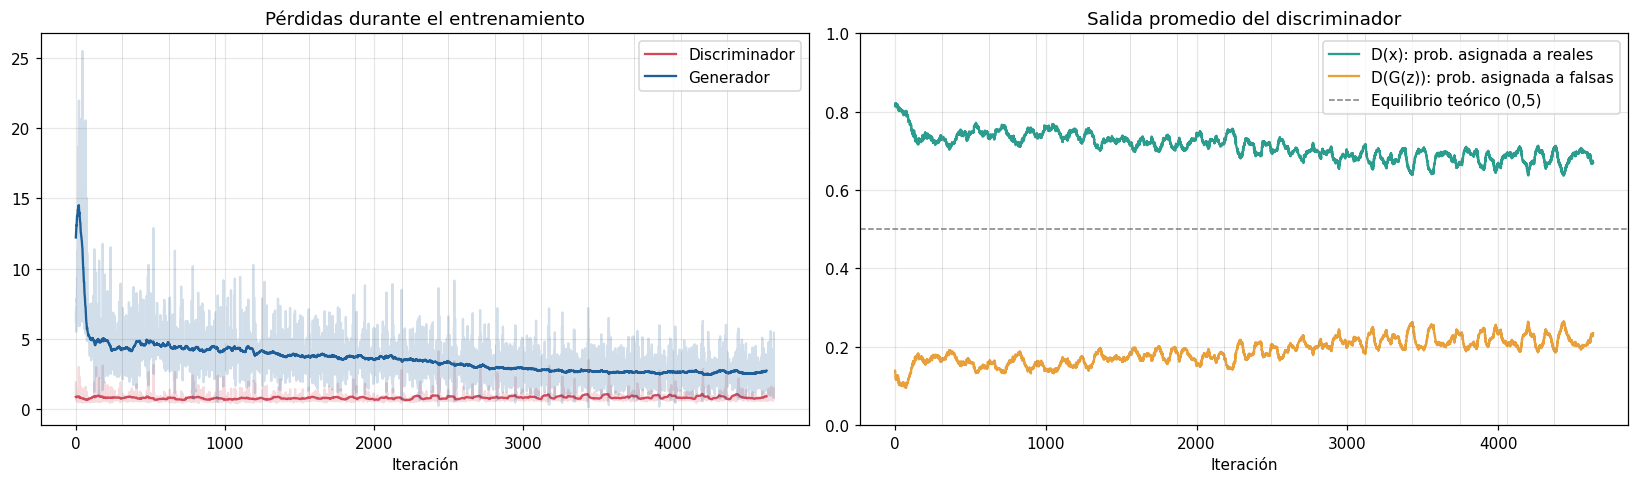

In [11]:
def suavizar(x, k=50):
    return np.convolve(x, np.ones(k) / k, mode="valid")

iters_por_epoca = len(cargador)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(historial["loss_D"], alpha=0.2, color="#d1495b"); axes[0].plot(suavizar(historial["loss_D"]), color="#d1495b", label="Discriminador")
axes[0].plot(historial["loss_G"], alpha=0.2, color="#1f5f99"); axes[0].plot(suavizar(historial["loss_G"]), color="#1f5f99", label="Generador")
axes[0].set_title("Pérdidas durante el entrenamiento"); axes[0].set_xlabel("Iteración"); axes[0].legend()

axes[1].plot(suavizar(historial["D_x"]), color="#2a9d8f", label="D(x): prob. asignada a reales")
axes[1].plot(suavizar(historial["D_G_z"]), color="#e9a03b", label="D(G(z)): prob. asignada a falsas")
axes[1].axhline(0.5, color="gray", ls="--", lw=1, label="Equilibrio teórico (0,5)")
axes[1].set_title("Salida promedio del discriminador"); axes[1].set_xlabel("Iteración"); axes[1].set_ylim(0, 1); axes[1].legend()
for ax in axes:
    for e in range(1, EPOCAS):
        ax.axvline(e * iters_por_epoca, color="gray", lw=0.4, alpha=0.4)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figuras/gan_curvas.png", bbox_inches="tight"); plt.show()

### 6.2 Evolución de las imágenes generadas (mismo ruido fijo)

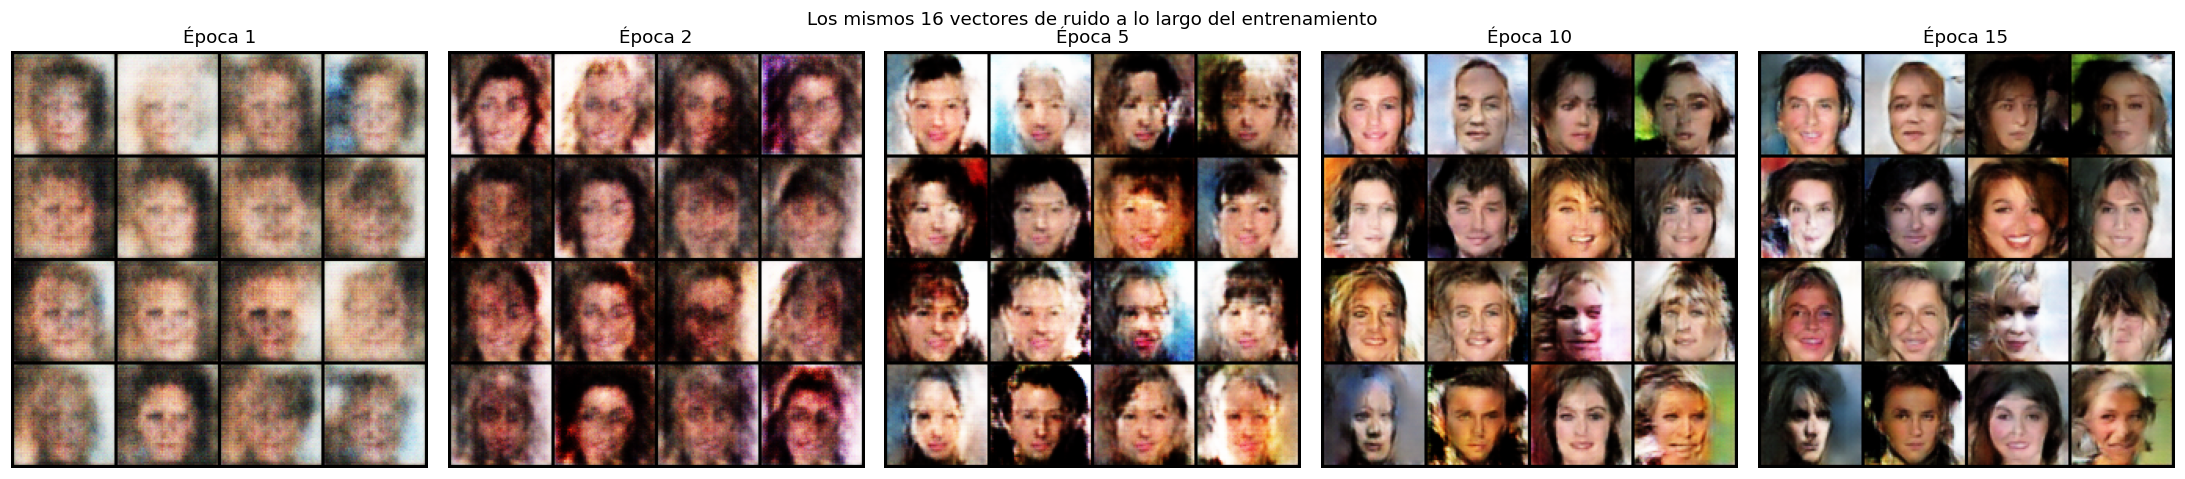

In [12]:
epocas_mostrar = sorted(set([1, 2, max(1, EPOCAS // 3), max(1, 2 * EPOCAS // 3), EPOCAS]))
fig, axes = plt.subplots(1, len(epocas_mostrar), figsize=(4 * len(epocas_mostrar), 4.4))
for ax, e in zip(axes, epocas_mostrar):
    rej = vutils.make_grid(rejillas_por_epoca[e - 1][:16], nrow=4, padding=2, normalize=True, value_range=(-1, 1))
    ax.imshow(rej.permute(1, 2, 0).numpy()); ax.set_title(f"Época {e}"); ax.axis("off")
plt.suptitle("Los mismos 16 vectores de ruido a lo largo del entrenamiento")
plt.tight_layout(); plt.savefig("figuras/gan_evolucion.png", bbox_inches="tight"); plt.show()

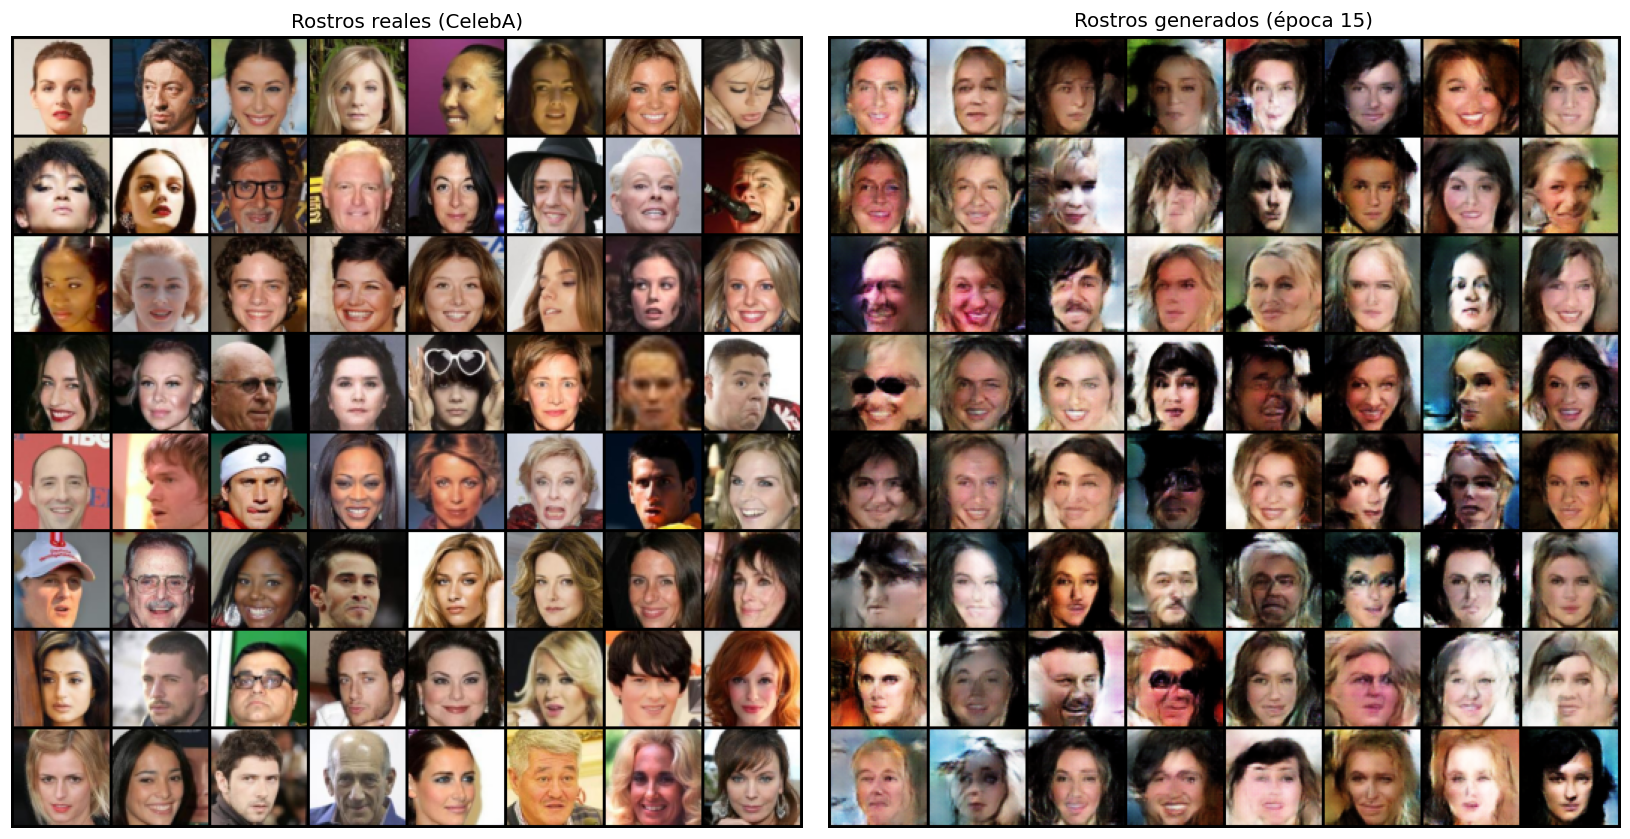

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, lote, titulo in [(axes[0], muestra_real.cpu(), "Rostros reales (CelebA)"),
                         (axes[1], rejillas_por_epoca[-1], f"Rostros generados (época {EPOCAS})")]:
    rej = vutils.make_grid(lote[:64], nrow=8, padding=2, normalize=True, value_range=(-1, 1))
    ax.imshow(rej.permute(1, 2, 0).numpy()); ax.set_title(titulo, fontsize=13); ax.axis("off")
plt.tight_layout(); plt.savefig("figuras/gan_reales_vs_generadas.png", bbox_inches="tight"); plt.show()

## 7. Explorando el espacio latente

Si el generador aprendió algo con sentido, el espacio latente debería ser "continuo": al moverme poco a poco entre dos vectores z, la cara debería transformarse de manera gradual y no saltar de forma caótica. Para comprobarlo hice una **interpolación esférica (slerp)** entre pares de vectores. Uso slerp en lugar de interpolación lineal porque los vectores gaussianos de alta dimensión viven cerca de una esfera.

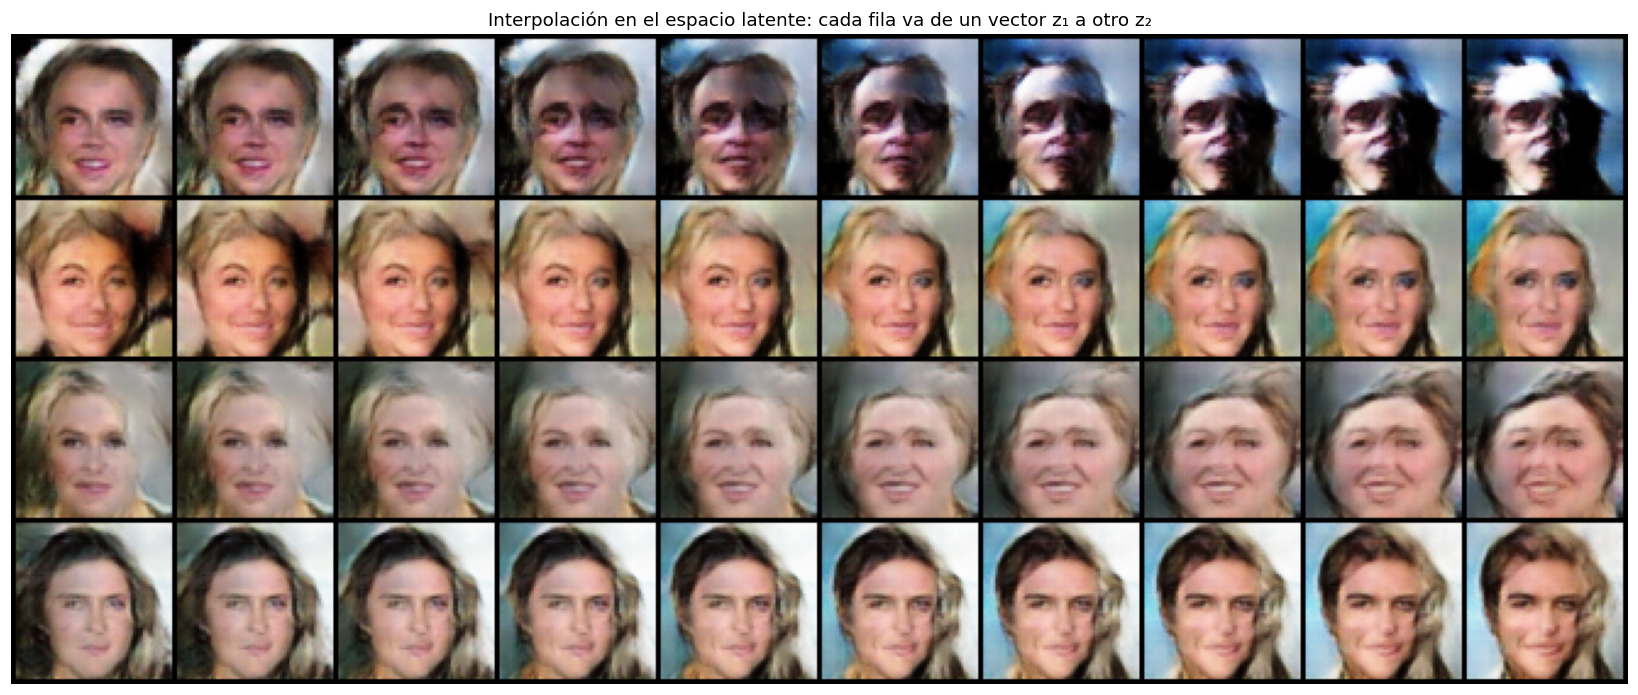

In [14]:
def slerp(z1, z2, t):
    a, b = z1.flatten(), z2.flatten()
    omega = torch.acos(torch.clamp(torch.dot(a / a.norm(), b / b.norm()), -1, 1))
    return ((torch.sin((1 - t) * omega) * z1 + torch.sin(t * omega) * z2) / torch.sin(omega))

torch.manual_seed(7)
filas = []
for _ in range(4):
    z1, z2 = torch.randn(NZ, 1, 1, device=device), torch.randn(NZ, 1, 1, device=device)
    filas.append(torch.stack([slerp(z1, z2, t) for t in torch.linspace(0, 1, 10)]))
with torch.no_grad():
    interpolaciones = G(torch.cat(filas)).cpu()
rej = vutils.make_grid(interpolaciones, nrow=10, padding=2, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(15, 6.5)); plt.imshow(rej.permute(1, 2, 0).numpy()); plt.axis("off")
plt.title("Interpolación en el espacio latente: cada fila va de un vector z₁ a otro z₂")
plt.tight_layout(); plt.savefig("figuras/gan_interpolacion.png", bbox_inches="tight"); plt.show()

## 8. Análisis de resultados

### 8.1 ¿El generador memorizó las fotos de entrenamiento?
Un riesgo de los modelos generativos es que simplemente "copien" imágenes del dataset. Para descartarlo, tomé varias caras generadas y busqué la imagen real **más parecida** (distancia euclidiana en píxeles) entre las 40.000 del entrenamiento. Si la red estuviera memorizando, el vecino más cercano sería casi idéntico.

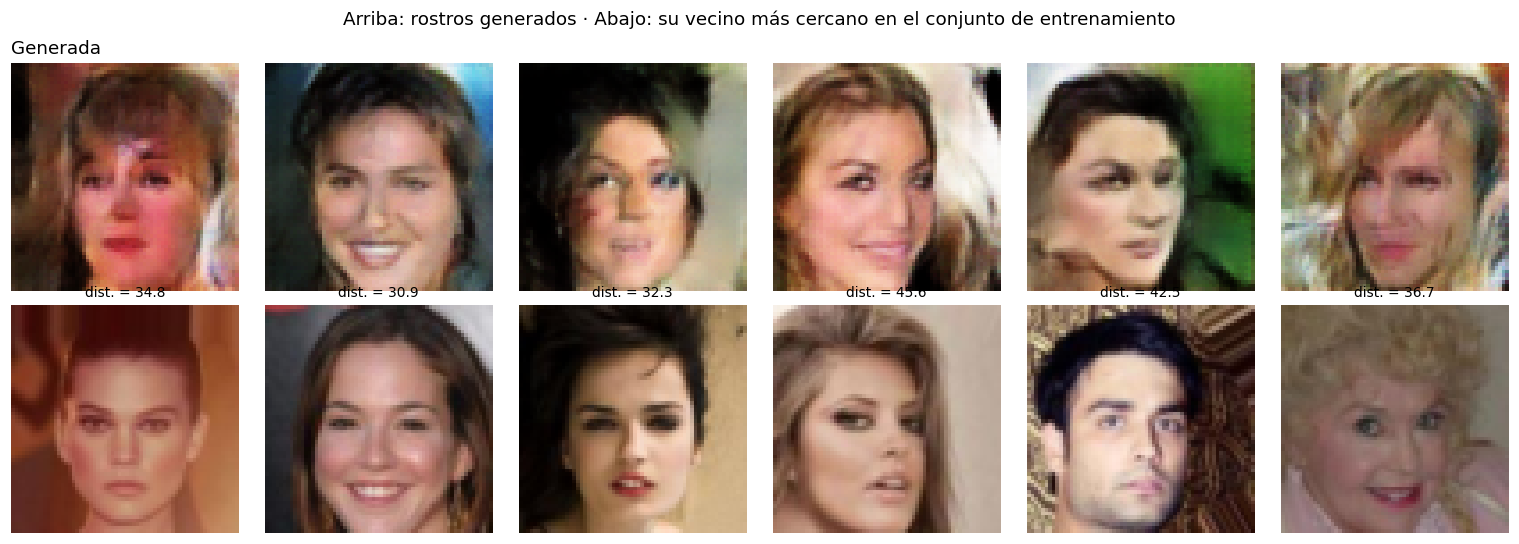

Distancia promedio generada → real más cercana: 37.1
Distancia promedio entre dos reales al azar:     81.0


In [15]:
torch.manual_seed(123)
with torch.no_grad():
    generadas = G(torch.randn(6, NZ, 1, 1, device=device))
gen_plana = generadas.reshape(6, -1)
mejores_d = torch.full((6,), float("inf"), device=device)
mejores_i = torch.zeros(6, dtype=torch.long, device=device)
for inicio in range(0, len(datos), 4096):
    bloque = a_rango_red(datos[inicio:inicio + 4096]).reshape(-1, gen_plana.shape[1])
    d = torch.cdist(gen_plana, bloque)
    dmin, imin = d.min(dim=1)
    mejora = dmin < mejores_d
    mejores_d[mejora] = dmin[mejora]; mejores_i[mejora] = imin[mejora] + inicio

vecinos = a_rango_red(datos[mejores_i.cpu()])
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for k in range(6):
    for fila, img in enumerate([generadas[k], vecinos[k]]):
        axes[fila, k].imshow(((img.permute(1, 2, 0).cpu() + 1) / 2).clamp(0, 1)); axes[fila, k].axis("off")
    axes[1, k].set_title(f"dist. = {mejores_d[k]:.1f}", fontsize=9)
axes[0, 0].set_title("Generada", loc="left"); axes[1, 0].set_ylabel("Real más cercana")
plt.suptitle("Arriba: rostros generados · Abajo: su vecino más cercano en el conjunto de entrenamiento")
plt.tight_layout(); plt.savefig("figuras/gan_vecinos.png", bbox_inches="tight"); plt.show()

# Referencia: distancia típica entre dos rostros reales distintos
idx = torch.randperm(len(datos))[:12]
reales_ref = a_rango_red(datos[idx]).reshape(12, -1)
d_ref = torch.cdist(reales_ref[:6], reales_ref[6:]).diagonal()
print(f"Distancia promedio generada → real más cercana: {mejores_d.mean():.1f}")
print(f"Distancia promedio entre dos reales al azar:     {d_ref.mean():.1f}")

### 8.2 ¿Hubo colapso de modo?
El **colapso de modo** pasa cuando el generador descubre unas pocas caras que engañan al discriminador y deja de producir variedad. Para medirlo de forma sencilla, comparé la **diversidad** (distancia promedio entre pares de imágenes) de 500 rostros generados con la de 500 rostros reales. Si hubiera colapso, la diversidad de los generados sería mucho menor.

In [16]:
with torch.no_grad():
    muestras_g = torch.cat([G(torch.randn(250, NZ, 1, 1, device=device)) for _ in range(2)])
muestras_r = a_rango_red(datos[torch.randperm(len(datos))[:500]])

def diversidad(x):
    x = F.interpolate(x, size=32, mode="area").reshape(len(x), -1)   # reduzco a 32x32 para comparar estructura
    d = torch.cdist(x, x)
    return d[~torch.eye(len(x), dtype=torch.bool, device=x.device)].mean().item()

div_g, div_r = diversidad(muestras_g), diversidad(muestras_r)
print(f"Diversidad de rostros reales:     {div_r:.2f}")
print(f"Diversidad de rostros generados:  {div_g:.2f}  ({div_g / div_r:.0%} de la diversidad real)")

Diversidad de rostros reales:     37.97
Diversidad de rostros generados:  38.50  (101% de la diversidad real)


In [17]:
n = len(cargador)
resumen = {
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "n_imagenes": N_IMAGENES, "epocas": EPOCAS, "batch": BATCH, "iteraciones_totales": len(historial["loss_D"]),
    "params_G": n_params(G), "params_D": n_params(D),
    "tiempo_total_min": round(sum(tiempos) / 60, 2), "tiempo_medio_epoca_s": round(float(np.mean(tiempos)), 1),
    "por_epoca": [{"epoca": e + 1,
                   "loss_D": round(float(np.mean(historial["loss_D"][e*n:(e+1)*n])), 3),
                   "loss_G": round(float(np.mean(historial["loss_G"][e*n:(e+1)*n])), 3),
                   "D_x": round(float(np.mean(historial["D_x"][e*n:(e+1)*n])), 3),
                   "D_G_z": round(float(np.mean(historial["D_G_z"][e*n:(e+1)*n])), 3)} for e in range(EPOCAS)],
    "dist_vecino_mas_cercano": round(mejores_d.mean().item(), 2), "dist_entre_reales": round(d_ref.mean().item(), 2),
    "diversidad_real": round(div_r, 3), "diversidad_generada": round(div_g, 3),
}
with open("resultados_gan.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)
print(json.dumps(resumen, ensure_ascii=False, indent=2))

{
  "gpu": "Tesla T4",
  "n_imagenes": 40000,
  "epocas": 15,
  "batch": 128,
  "iteraciones_totales": 4680,
  "params_G": 3576704,
  "params_D": 2765568,
  "tiempo_total_min": 13.0,
  "tiempo_medio_epoca_s": 52.0,
  "por_epoca": [
    {
      "epoca": 1,
      "loss_D": 0.84,
      "loss_G": 6.79,
      "D_x": 0.76,
      "D_G_z": 0.149
    },
    {
      "epoca": 2,
      "loss_D": 0.795,
      "loss_G": 4.539,
      "D_x": 0.738,
      "D_G_z": 0.162
    },
    {
      "epoca": 3,
      "loss_D": 0.769,
      "loss_G": 4.352,
      "D_x": 0.741,
      "D_G_z": 0.155
    },
    {
      "epoca": 4,
      "loss_D": 0.749,
      "loss_G": 4.245,
      "D_x": 0.747,
      "D_G_z": 0.151
    },
    {
      "epoca": 5,
      "loss_D": 0.777,
      "loss_G": 3.921,
      "D_x": 0.728,
      "D_G_z": 0.169
    },
    {
      "epoca": 6,
      "loss_D": 0.807,
      "loss_G": 3.746,
      "D_x": 0.718,
      "D_G_z": 0.179
    },
    {
      "epoca": 7,
      "loss_D": 0.789,
      "loss_G": 

## 9. Conclusiones

- **La GAN mínima llegó al equilibrio que predice la teoría.** En el mundo de 2×2 píxeles, el discriminador aprendió pesos positivos en la diagonal principal (1,10 y 0,37) y negativos en la otra (−0,29 y −0,89). Es la misma regla de "sumar la diagonal y restar los opuestos" que hicimos a mano en clase. El generador terminó produciendo caras casi perfectas (≈ [0,97; 0,03; 0,03; 0,96]). Lo más interesante es que el discriminador ya no logra diferenciarlas: le da 0,53 a una cara real, prácticamente una moneda al aire. Además, los errores se estabilizaron cerca de los valores teóricos del equilibrio: 2·ln 2 ≈ 1,39 para el discriminador y ln 2 ≈ 0,69 para el generador.
- **La DCGAN aprendió a dibujar rostros en solo 15 épocas.** Fueron 4.680 iteraciones en unos 13 minutos en una GPU T4. Con el mismo ruido fijo se ve el avance:
  - Época 1: manchas con forma de cara.
  - Época 5: rostros reconocibles.
  - Épocas 10 a 15: cabello, sonrisas, distintos tonos de piel, hombres y mujeres, y algunas caras con gafas.
- **El generador fue ganando terreno, pero el discriminador sigue adelante.** La pérdida del generador bajó de 6,79 a 2,63. La probabilidad que el discriminador le asigna a las falsas, D(G(z)), subió de 0,15 a 0,22, y la que le asigna a las reales, D(x), bajó de 0,76 a 0,68. No se llegó al equilibrio ideal de 0,5, lo que indica que con más épocas el generador todavía podía mejorar.
- **El espacio latente es continuo.** En la interpolación, la mayoría de las filas muestran transiciones suaves de una cara a otra: cambian el peinado, la iluminación y la expresión. En una de ellas, la transición pasa por una zona donde el rostro se deforma. Esto muestra que no todo el espacio latente está igual de bien aprendido.
- **No hay memorización ni colapso de modo.**
  - Los vecinos más cercanos de las caras generadas son personas claramente distintas. La distancia promedio al vecino más cercano fue 37,1, frente a 81,0 entre dos reales tomadas al azar. Es lógico que sea menor, porque se busca el mínimo entre 40.000 fotos, pero visualmente no son copias.
  - La diversidad de las caras generadas fue el 101 % de la de las reales (38,50 contra 37,97).
- **Limitaciones.** Los rostros todavía tienen artefactos: ojos asimétricos, fondos borrosos y gafas "manchadas". Para acercarse a resultados como los de *This Person Does Not Exist* (StyleGAN) harían falta más resolución, más datos, muchas más horas de entrenamiento y arquitecturas más avanzadas.